In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
!pip install -q legacy-cgi opendatasets

In [3]:
import os
import random
import pandas as pd
from pathlib import Path
import opendatasets as od
import shutil
import glob
import time
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from tqdm.auto import tqdm

In [5]:
# Define the variable before checking
RAW_DIR = 'kitchenware-classification'

if Path(RAW_DIR).is_dir():
    print('The dataset already exists. Skipping download...')
else:
    print('Downloading the dataset...')
    od.download('https://www.kaggle.com/competitions/kitchenware-classification/data')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: raunakgola
Your Kaggle Key: ··········


100%|██████████| 1.63G/1.63G [00:18<00:00, 93.1MB/s]



Extracting archive ./kitchenware-classification/kitchenware-classification.zip to ./kitchenware-classification


# sample folder first

In [6]:
import pandas as pd, random, shutil, os

CLASSES = ["plate", "spoon", "fork", "knife", "cup", "glass"]
PER_CLASS = 150

df = pd.read_csv("/content/kitchenware-classification/train.csv", dtype={"Id": str})

sampled_ids = []
for cls in CLASSES:
    cls_ids = df.loc[df["label"] == cls, "Id"].tolist()
    if len(cls_ids) < PER_CLASS:
        raise ValueError(f"Only {len(cls_ids)} images available for '{cls}', need {PER_CLASS}")
    sampled_ids.extend(random.sample(cls_ids, PER_CLASS))

os.makedirs("sample_900/images", exist_ok=True)
for img_id in sampled_ids:
    shutil.copy(f"/content/kitchenware-classification/images/{img_id}.jpg", f"sample_900/images/{img_id}.jpg")

print(f"Copied {len(sampled_ids)} images ({PER_CLASS} per class x {len(CLASSES)} classes)")

Copied 900 images (150 per class x 6 classes)


# configure the folders on input and output

In [7]:
IMAGES_DIR = "/content/sample_900/images"
LABELS_DIR = "/content/sample_900/labels"
os.makedirs(LABELS_DIR, exist_ok=True)

# config for Annotation of data

In [8]:
BATCH_SIZE = 4
BOX_THRESHOLD = 0.35
TEXT_THRESHOLD = 0.30
USE_FP16 = True  # flip to False to re-run as a clean fp32 control on this same code path

# prompt for grounding DINO and classes index

In [9]:
CLASSES = ["plate", "spoon", "fork", "knife", "cup", "glass"]
TEXT_PROMPT = " . ".join(CLASSES) + " ."
CLASS_MAP = {c: i for i, c in enumerate(CLASSES)}
print(TEXT_PROMPT)
print(CLASS_MAP)

plate . spoon . fork . knife . cup . glass .
{'plate': 0, 'spoon': 1, 'fork': 2, 'knife': 3, 'cup': 4, 'glass': 5}


# device agnostic code and model id

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "IDEA-Research/grounding-dino-base"

# Load the Grounding DINO processor and model onto the GPU

In [11]:
processor = AutoProcessor.from_pretrained(model_id)

# Model stays in fp32 -- autocast decides per-op precision at runtime instead
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to(device)
model.eval()

print("Processor default resize target:", processor.image_processor.size)

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Processor default resize target: SizeDict(height=None, width=None, longest_edge=1333, shortest_edge=800, max_height=None, max_width=None)


# Dataset + collate function: batch-load images from disk, skipping any that fail to open

In [12]:

class ImageBatchDataset(Dataset):
    def __init__(self, image_paths):
        self.image_paths = image_paths
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        path = self.image_paths[idx]
        image_id = os.path.splitext(os.path.basename(path))[0]
        try:
            img = Image.open(path).convert("RGB")
            return img, image_id, True
        except Exception:
            return Image.new("RGB", (640, 640)), image_id, False

def collate_fn(batch):
    imgs = [b[0] for b in batch if b[2]]
    ids  = [b[1] for b in batch if b[2]]
    return imgs, ids

# Build the dataset and batched dataloader

In [13]:
image_paths = sorted(glob.glob(f"{IMAGES_DIR}/*.jpg"))
dataset = ImageBatchDataset(image_paths)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=2)

print(f"Testing {len(image_paths)} images | batch_size={BATCH_SIZE} | fp16={USE_FP16}")

Testing 900 images | batch_size=4 | fp16=True


# Initialize counters and start the run timer

In [14]:
labeled_count, skipped_count = 0, 0
t_start = time.time()

# Main inference loop: run detection batch by batch and write YOLO label files

In [15]:
with torch.no_grad():
    for batch_idx, (imgs, ids) in enumerate(tqdm(dataloader, desc="Batches")):
        if not imgs:
            continue
        t0 = time.time()

        text_queries = [TEXT_PROMPT] * len(imgs)
        inputs = processor(images=imgs, text=text_queries, return_tensors="pt").to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_FP16):
            outputs = model(**inputs)

        target_sizes = [img.size[::-1] for img in imgs]
        results = processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids,
            threshold=BOX_THRESHOLD, text_threshold=TEXT_THRESHOLD,
            target_sizes=target_sizes
        )

        for i, (image_id, result) in enumerate(zip(ids, results)):
            boxes, scores, labels = result["boxes"].cpu().numpy(), result["scores"].cpu().numpy(), result["labels"]
            print(f"  {image_id}: {list(zip(labels, [round(float(s),2) for s in scores]))}")

            if len(boxes) == 0:
                skipped_count += 1
                continue

            orig_w, orig_h = imgs[i].size
            label_file = os.path.join(LABELS_DIR, f"{image_id}.txt")
            valid = 0
            with open(label_file, "w") as f:
                for box, score, label in zip(boxes, scores, labels):
                    clean_label = label.strip().lower()
                    if clean_label not in CLASS_MAP:
                        continue
                    class_id = CLASS_MAP[clean_label]
                    x1, y1, x2, y2 = box
                    cx, cy = ((x1+x2)/2)/orig_w, ((y1+y2)/2)/orig_h
                    bw, bh = (x2-x1)/orig_w, (y2-y1)/orig_h
                    cx, cy = max(0,min(1,cx)), max(0,min(1,cy))
                    bw, bh = max(0,min(1,bw)), max(0,min(1,bh))
                    f.write(f"{class_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")
                    valid += 1
            labeled_count += 1 if valid > 0 else 0
            skipped_count += 1 if valid == 0 else 0

        print(f"  batch {batch_idx}: {time.time()-t0:.2f}s")

Batches:   0%|          | 0/225 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:89: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


  0005: [('spoon', 0.72), ('knife', 0.45)]
  0032: [('spoon', 0.73)]
  0045: [('cup', 0.6), ('glass', 0.39)]
  0049: [('plate', 0.57), ('cup', 0.39)]
  batch 0: 6.34s
  0064: [('glass', 0.72)]
  0069: [('cup', 0.45), ('glass', 0.44)]
  0075: [('spoon', 0.66)]
  0082: [('cup', 0.61), ('glass', 0.47)]
  batch 1: 2.01s
  0084: [('knife', 0.83)]
  0094: [('cup glass', 0.51)]
  0106: [('fork', 0.6)]
  0107: [('plate', 0.78)]
  batch 2: 2.92s
  0108: [('cup', 0.55), ('glass', 0.52), ('plate', 0.37)]
  0113: [('knife', 0.57)]
  0115: [('knife', 0.82), ('plate', 0.5), ('plate', 0.37)]
  0117: [('plate', 0.77)]
  batch 3: 1.37s
  0122: [('cup glass', 0.6)]
  0129: [('cup glass', 0.53)]
  0144: [('fork', 0.82)]
  0148: [('cup', 0.48), ('glass', 0.55)]
  batch 4: 2.14s
  0153: [('cup glass', 0.58)]
  0165: [('plate', 0.77)]
  0170: [('knife', 0.66)]
  0174: [('fork', 0.79), ('cup', 0.53), ('plate', 0.39), ('glass', 0.41)]
  batch 5: 1.29s
  0177: [('plate', 0.76)]
  0187: [('fork', 0.83)]
  0194:

# Print final summary: total time, VRAM usage, labeled/skipped counts

In [16]:
elapsed = time.time() - t_start
allocated = torch.cuda.max_memory_allocated() / 1e9
reserved  = torch.cuda.max_memory_reserved() / 1e9

print(f"\nDone in {elapsed:.1f}s | Labeled: {labeled_count} | Skipped: {skipped_count}")
print(f"Peak VRAM -- allocated: {allocated:.2f} GB | reserved: {reserved:.2f} GB  (reserved is closer to what Colab's monitor shows)")
if labeled_count:
    print(f"Estimated full 9367-image run: {(elapsed/len(image_paths)*9367)/60:.1f} min")


Done in 483.9s | Labeled: 802 | Skipped: 98
Peak VRAM -- allocated: 11.15 GB | reserved: 11.56 GB  (reserved is closer to what Colab's monitor shows)
Estimated full 9367-image run: 83.9 min


Found 900 total images | 900 have label files


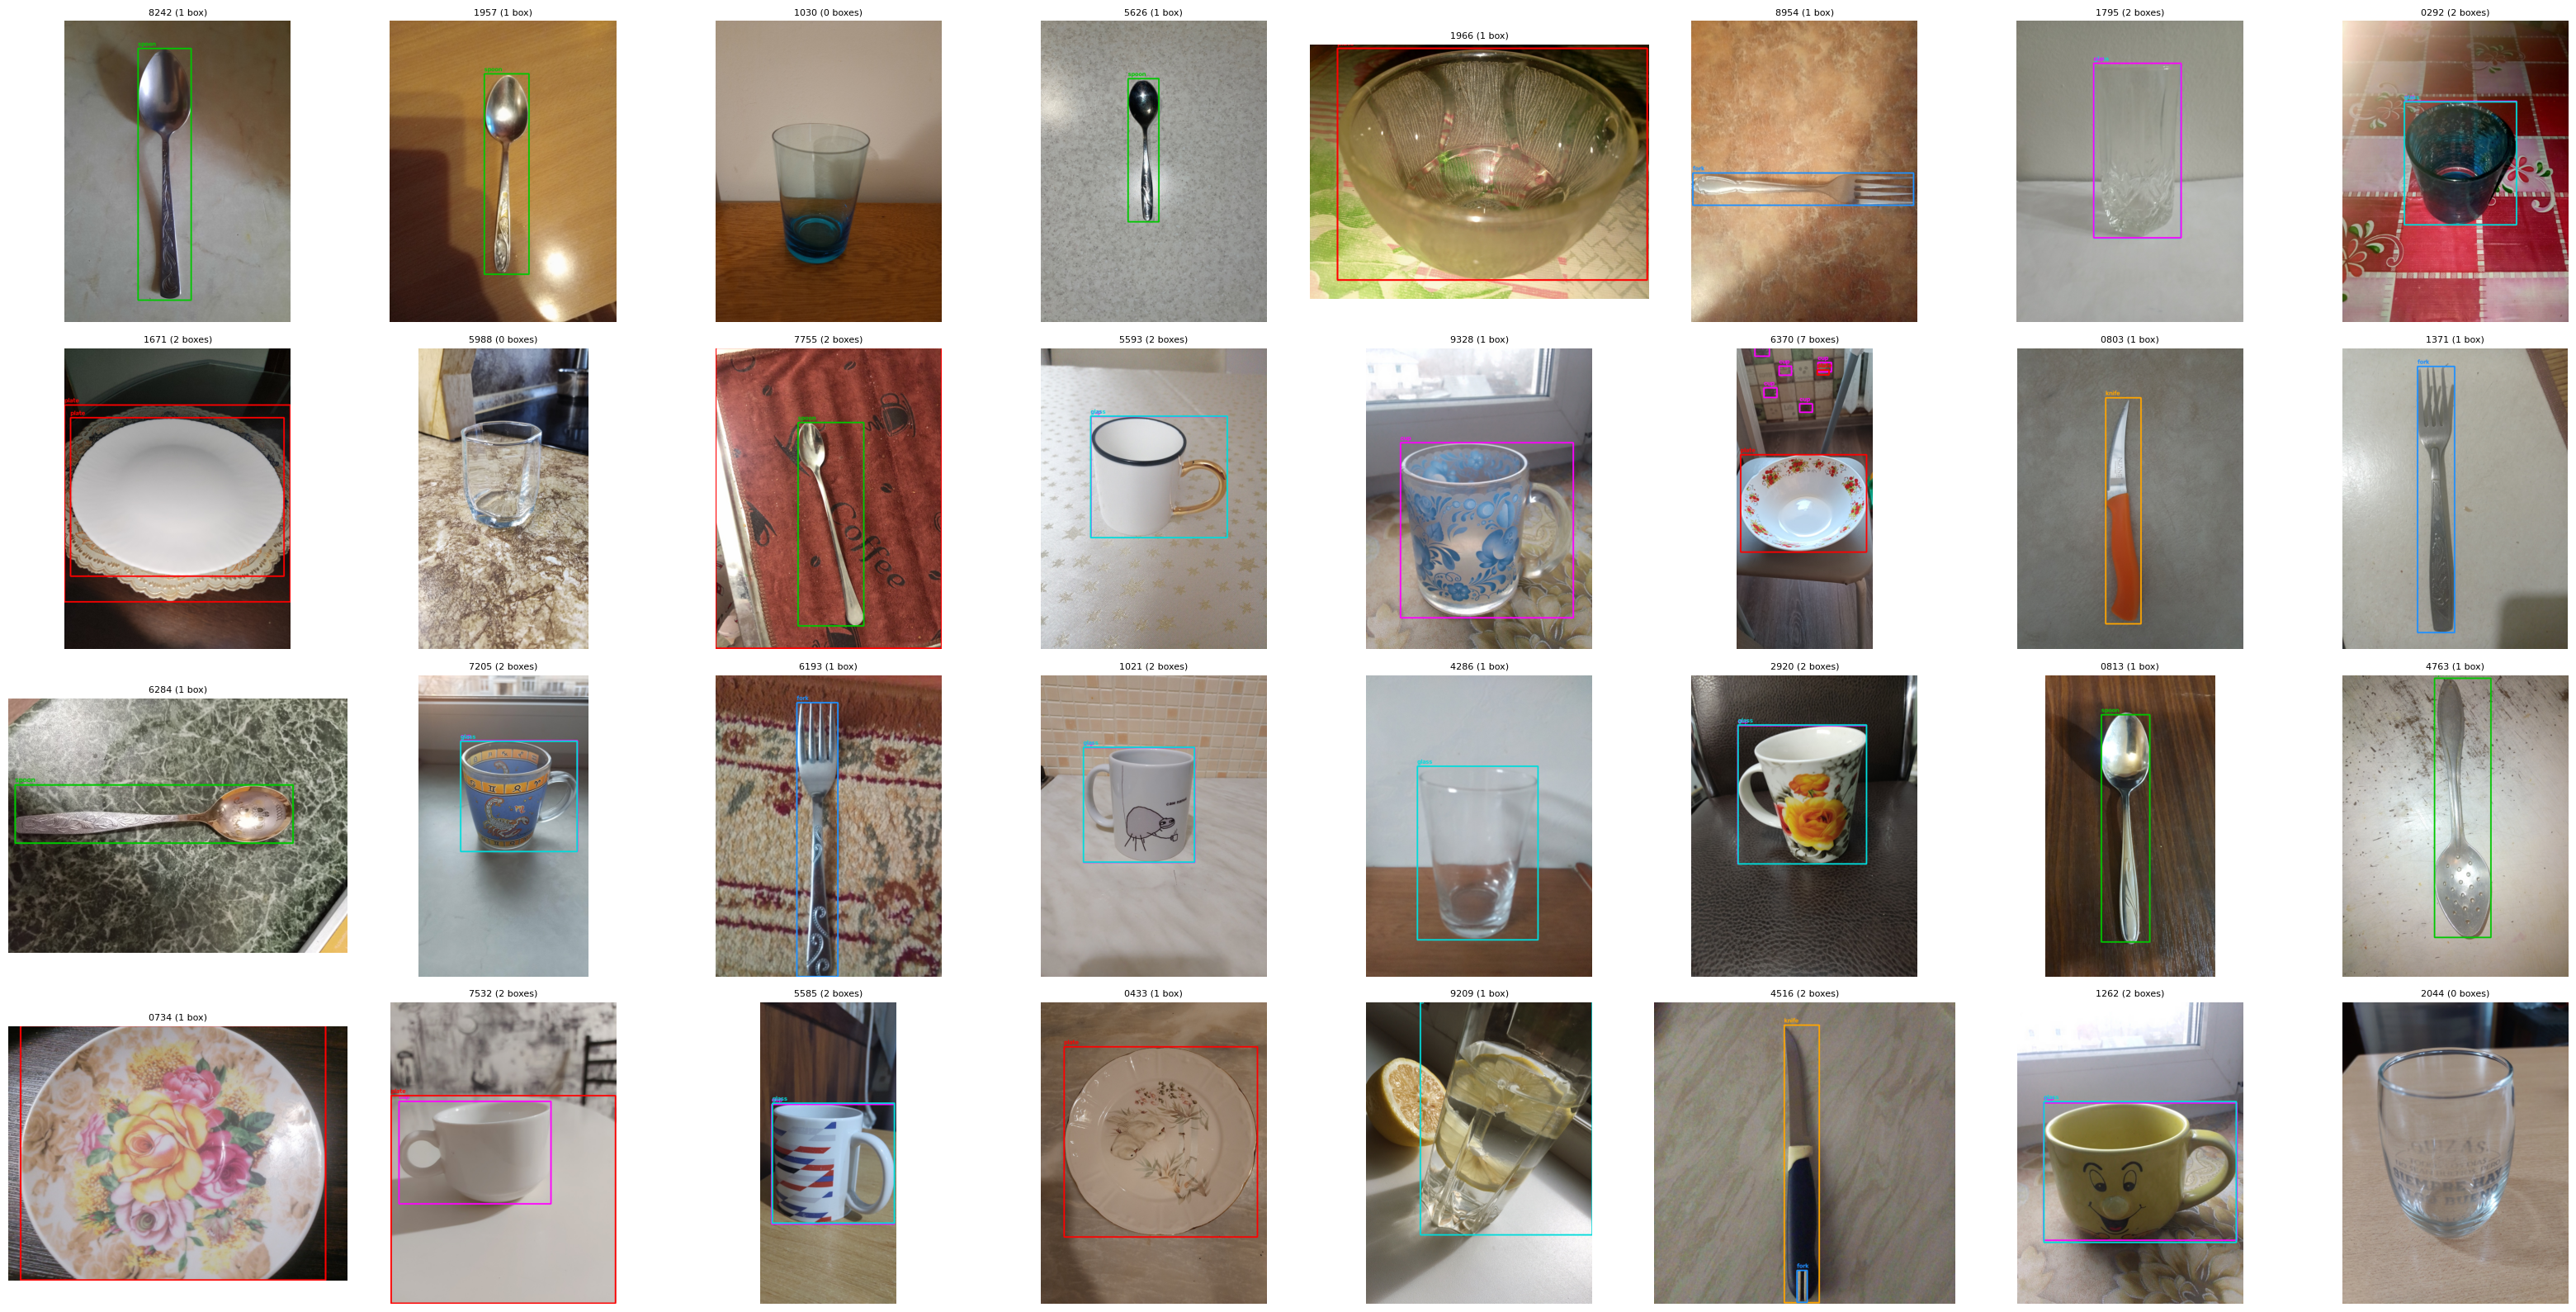

In [17]:
import os
import glob
import random
import cv2 as cv
import matplotlib.pyplot as plt

IMAGES_DIR = "/content/sample_900/images"
LABELS_DIR = "/content/sample_900/labels"
os.makedirs(LABELS_DIR, exist_ok=True)

CLASS_NAMES = ['plate', 'spoon', 'fork', 'knife', 'cup', 'glass']
CLASS_COLORS = {
    0: (255, 0, 0),     # plate - red
    1: (0, 200, 0),     # spoon - green
    2: (30, 144, 255),  # fork  - blue
    3: (255, 165, 0),   # knife - orange
    4: (255, 0, 255),   # cup   - magenta
    5: (0, 220, 220),   # glass - cyan
}

ROWS, COLS = 4, 8
N_SAMPLES = ROWS * COLS

# Only sample from images that actually have a matching label file --
# LABELS_DIR may only contain a subset if not every image has been auto-labeled yet
all_image_paths = sorted(glob.glob(f"{IMAGES_DIR}/*.jpg"))
available_ids = [
    os.path.splitext(os.path.basename(p))[0] for p in all_image_paths
    if os.path.exists(f"{LABELS_DIR}/{os.path.splitext(os.path.basename(p))[0]}.txt")
]

print(f"Found {len(all_image_paths)} total images | {len(available_ids)} have label files")

n = min(N_SAMPLES, len(available_ids))
sample_ids = random.sample(available_ids, n)

fig, axes = plt.subplots(ROWS, COLS, figsize=(4 * COLS, 4 * ROWS))
axes = axes.flat

for ax, image_id in zip(axes, sample_ids):
    img_path = f'{IMAGES_DIR}/{image_id}.jpg'
    label_path = f'{LABELS_DIR}/{image_id}.txt'

    img = cv.imread(img_path)
    if img is None:
        ax.axis('off')
        continue

    img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    n_boxes = 0
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                cls, cx, cy, bw, bh = map(float, parts[:5])
                cls = int(cls)
                x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
                x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)

                color = CLASS_COLORS.get(cls, (255, 255, 255))
                cv.rectangle(img, (x1, y1), (x2, y2), color, 3)
                cv.putText(
                    img, CLASS_NAMES[cls], (x1, max(y1 - 8, 0)),
                    cv.FONT_HERSHEY_SIMPLEX, 0.7, color, 2
                )
                n_boxes += 1

    ax.imshow(img)
    ax.set_title(f"{image_id} ({n_boxes} box{'es' if n_boxes != 1 else ''})", fontsize=8)
    ax.axis('off')

# Hide any unused subplot cells
for ax in list(axes)[len(sample_ids):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [18]:
shutil.make_archive("sample_900", "zip", "sample_900")

'/content/sample_900.zip'